### Comparison between SteadierCom and experimental results

In [1]:
import pandas as pd
import numpy as np
import json
import csv
import warnings
from os import listdir
from collections import defaultdict

import matplotlib.pyplot as plt
import seaborn as sns

import scipy as sp
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,recall_score,precision_score,classification_report

import sys

sys.path.append("../functions/")

import compare_exp_sim

In [2]:
%load_ext autoreload
%autoreload 2

#### Mapping names to seed ids (seem to have a good overlap)

In [3]:
with open("../data/Venturelli2018/generated/metid2metname.json") as file:
    metid2metname = json.load(file)
    
with open("../data/Venturelli2018/generated/metname2metanetx.json") as file:
    metname2metanetx = json.load(file)
    
with open("../data/Venturelli2018/generated/metname_groups.json") as file:
    metname_groups = json.load(file)

with open("../data/Venturelli2018/generated/metname2group.json") as file:
    metname2group = json.load(file)

with open("../data/Venturelli2018/generated/metid2group.json") as file:
    metid2group = json.load(file)

In [4]:
len(set(metname2metanetx.keys())-set(metid2metname.values()))

33

**Metabolomics**

In [5]:
dataset4 = pd.read_excel("../data/Venturelli2018/msb178157-sup-0005-datasetev4.xlsx",sheet_name="Dataset EV4",index_col=0)
signal_exp = compare_exp_sim.prepare_exp_met_venturelli(dataset4,metname_groups,metname2group)

**Load steadiercom results**

In [6]:
dfs = []
for file in listdir("../output/Venturelli2018/results_steadiercom/results_abundance/"):
    if file.endswith(".tsv") and (not file.endswith("growth.tsv")):
    
        df = pd.read_csv("../output/Venturelli2018/results_steadiercom/results_abundance/"+file,sep="\t")
        dfs.append(df)
steadiercom_abundance = pd.concat(dfs)
steadiercom_abundance = steadiercom_abundance[steadiercom_abundance.community=="NONE"]

dfs = []
for file in listdir("../output/Venturelli2018/results_steadiercom/results_growth/"):
    if file.endswith(".tsv") and (not file.endswith("abundance.tsv")):
        df = pd.read_csv("../output/Venturelli2018/results_steadiercom/results_growth/"+file,sep="\t")
        dfs.append(df)
steadiercom_growth = pd.concat(dfs)
steadiercom_growth = steadiercom_growth[steadiercom_growth.community=="NONE"]


dfs = []
for file in listdir("../output/Venturelli2018/results_steadiercom/results_growth_abundance/"):
    if file.endswith(".tsv"):
        df = pd.read_csv("../output/Venturelli2018/results_steadiercom/results_growth_abundance/"+file,sep="\t")
        dfs.append(df)
steadiercom_growth_abundance = pd.concat(dfs)
steadiercom_growth_abundance = steadiercom_growth_abundance[steadiercom_growth_abundance.community=="NONE"]


**Load smetana results**

In [7]:
smetana = pd.read_csv("../output/Venturelli2018/smetana/no_coupling_detailed.tsv",sep="\t")

smetana = smetana[smetana.community=="Full"]

**Load steadycom results**

In [8]:
steadycom_fixed_abundance = pd.read_csv("../output/Venturelli2018/steadycom/cross_feeding_fixed_abundance.tsv",sep="\t")
steadycom_fixed_abundance = steadycom_fixed_abundance[steadycom_fixed_abundance.community=="NONE"]
steadycom = pd.read_csv("../output/Venturelli2018/steadycom/cross_feeding.tsv",sep="\t")
steadycom = steadycom[steadycom.community=="NONE"]

steadycom.donor = steadycom.donor.map(lambda x: x.replace("M_","") if isinstance(x,str) else x)
steadycom.receiver = steadycom.receiver.map(lambda x: x.replace("M_","") if isinstance(x,str) else x)

steadycom_fixed_abundance.donor = steadycom_fixed_abundance.donor.map(lambda x: x.replace("M_","") if isinstance(x,str) else x)
steadycom_fixed_abundance.receiver = steadycom_fixed_abundance.receiver.map(lambda x: x.replace("M_","") if isinstance(x,str) else x)

**Process data - add met_group to columns**

In [9]:
steadiercom_dict = {
    "SteadierCom - fixed growth":steadiercom_growth,
    "SteadierCom - fixed growth & abundance":steadiercom_growth_abundance,
    "SteadierCom - fixed abundance":steadiercom_abundance
}

steadycom_dict = {
    "SteadyCom - Nothing fixed":steadycom,
    "SteadyCom - Fixed  abundance":steadycom_fixed_abundance
}

smetana_dict = {"Smetana":smetana}

simulation_sources = {
    "steadiercom": steadiercom_dict,
    "steadycom": steadycom_dict,
    "smetana": smetana_dict
}
simulation_dict = compare_exp_sim.prepare_all_simulations_venturelli(simulation_sources, metid2group,verbose=True)

[INFO] prepare_sim_met_venturelli removes environment from receivers and all compounds that are not found in metabolomics and map to AGORA identifiers
[INFO] prepare_sim_met_venturelli removes environment from receivers and all compounds that are not found in metabolomics and map to AGORA identifiers
[INFO] prepare_sim_met_venturelli removes environment from receivers and all compounds that are not found in metabolomics and map to AGORA identifiers
[INFO] prepare_sim_met_venturelli removes environment from receivers and all compounds that are not found in metabolomics and map to AGORA identifiers
[INFO] prepare_sim_met_venturelli removes environment from receivers and all compounds that are not found in metabolomics and map to AGORA identifiers
[INFO] prepare_sim_met_venturelli removes environment from receivers and all compounds that are not found in metabolomics and map to AGORA identifiers
[INFO] prepare_sim_met_venturelli removes environment from donors and all compounds that are n

## Scatterplots


Seeing if there is a relationship between simulated and experimental results

### NOTE
- We expect a **negative trend** for receiving rate/frequency with change in concentration. 
- We expect a **positive trend** for receiving rate/frequency with change in concentration. 

#### Receivers - SteadierCom - scatterplot - frequency

[INFO] plot_scatter_plots uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


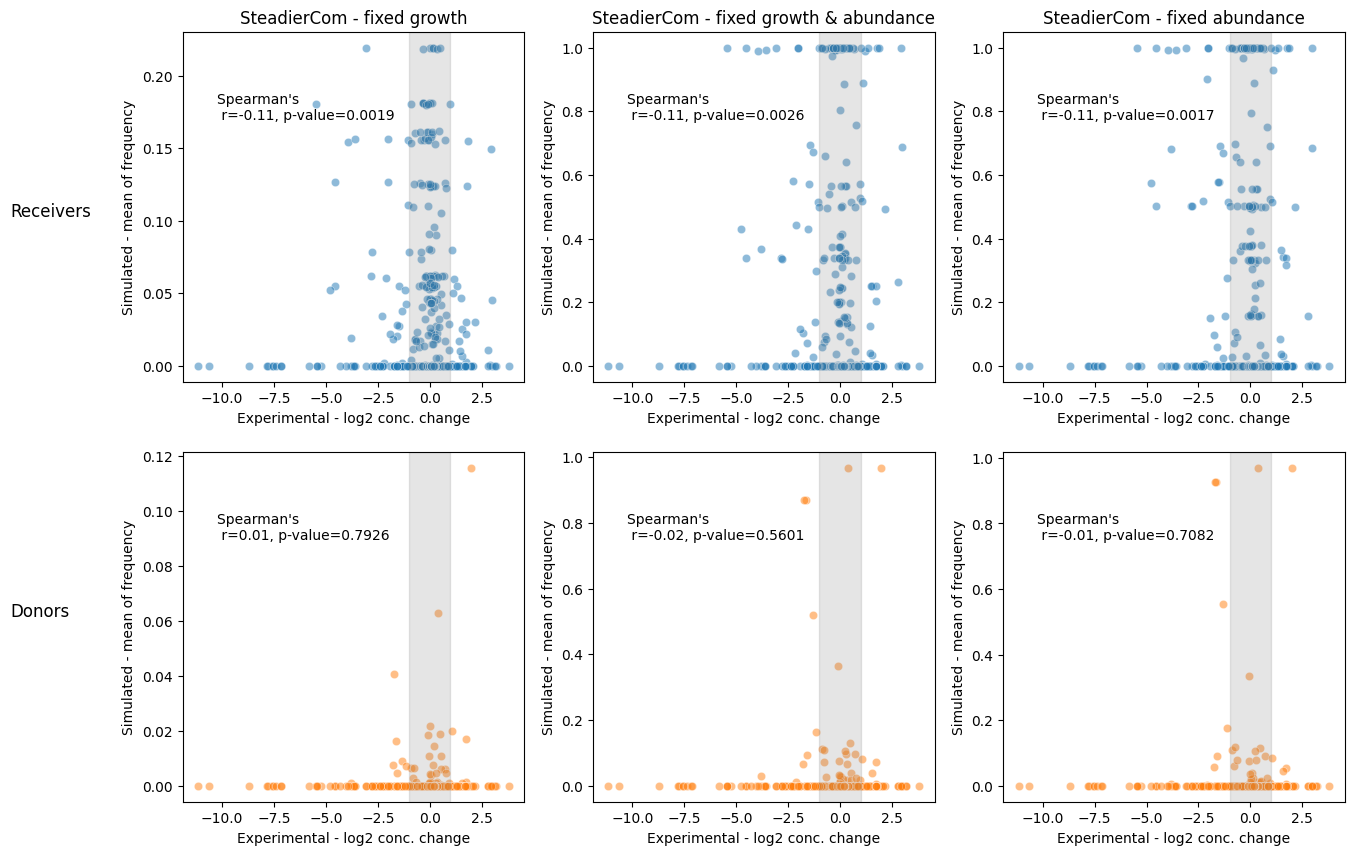

In [10]:
simulation_method="steadiercom"
receiver_or_donor="receiver"
agg_method ="mean"
metric = "frequency"
fig,axs = compare_exp_sim.plot_scatter_plots(simulation_dict,
                                             signal_exp,
                   simulation_method=simulation_method,
                   receiver_or_donor=receiver_or_donor,
                   agg_method=agg_method,
                   metric=metric)


#### Receivers - SteadierCom - scatterplot - rate

[INFO] plot_scatter_plots uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


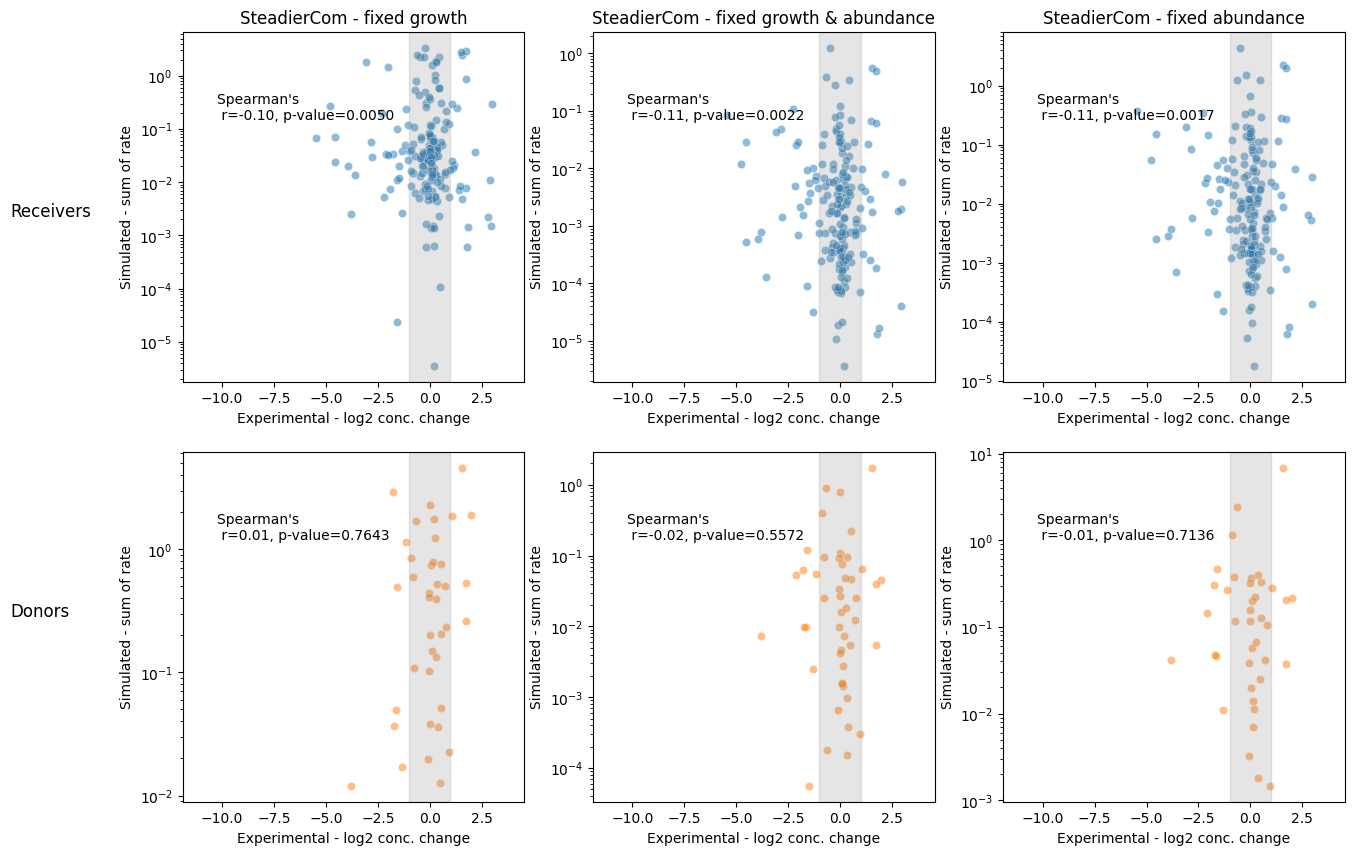

In [11]:
simulation_method="steadiercom"
receiver_or_donor="receiver"
agg_method ="sum"
metric = "rate"

fig,axs = compare_exp_sim.plot_scatter_plots(simulation_dict,
                                             signal_exp,
                   simulation_method=simulation_method,
                   receiver_or_donor=receiver_or_donor,
                   agg_method=agg_method,
                   metric=metric)

#### Receivers - SteadierCom - scatterplot - mass_rate

[INFO] plot_scatter_plots uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


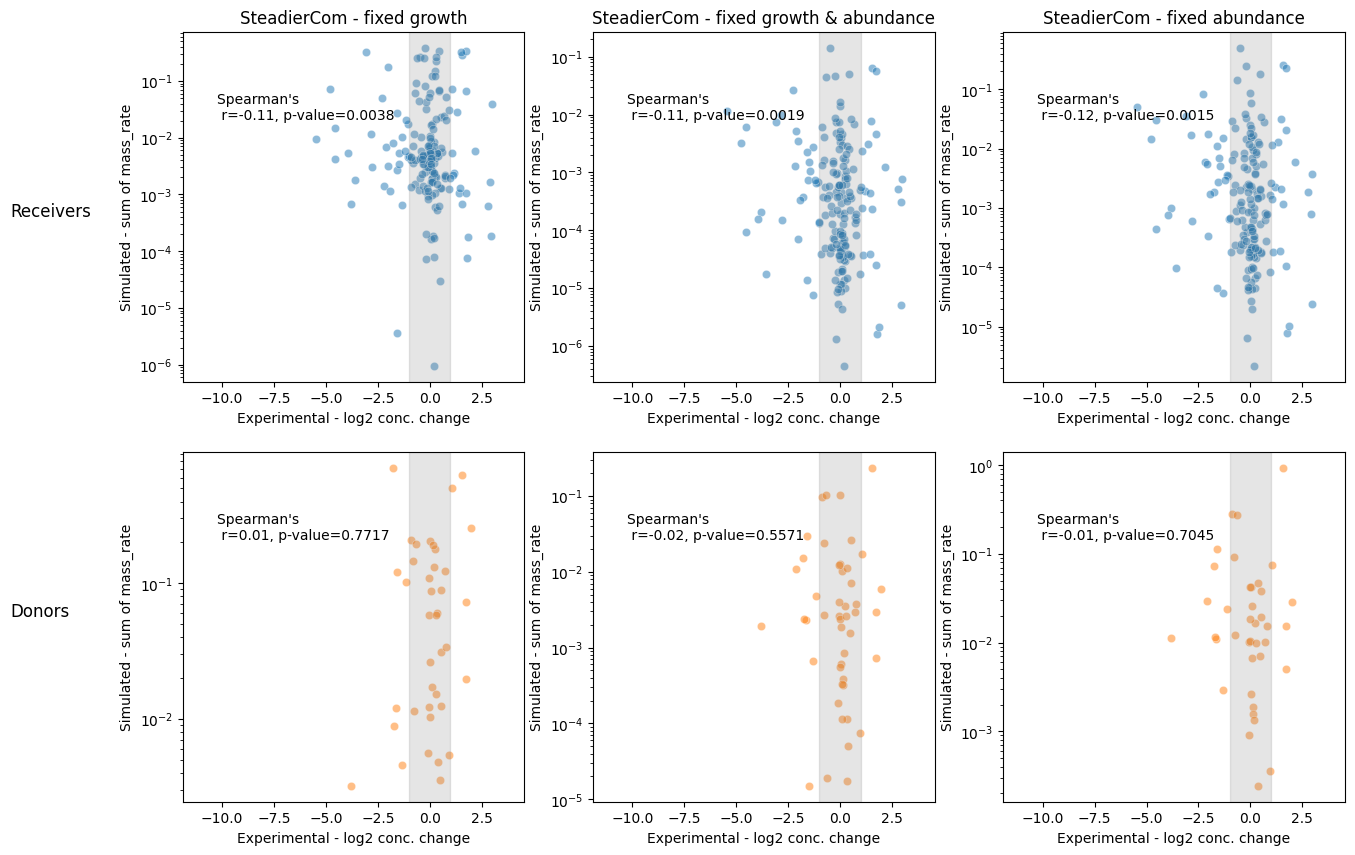

In [12]:
simulation_method="steadiercom"
receiver_or_donor="receiver"
agg_method ="sum"
metric = "mass_rate"

fig,axs = compare_exp_sim.plot_scatter_plots(simulation_dict,
                                             signal_exp,
                   simulation_method=simulation_method,
                   receiver_or_donor=receiver_or_donor,
                   agg_method=agg_method,
                   metric=metric)

#### Receivers - SteadyCom - scatterplot

[INFO] plot_scatter_plots uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


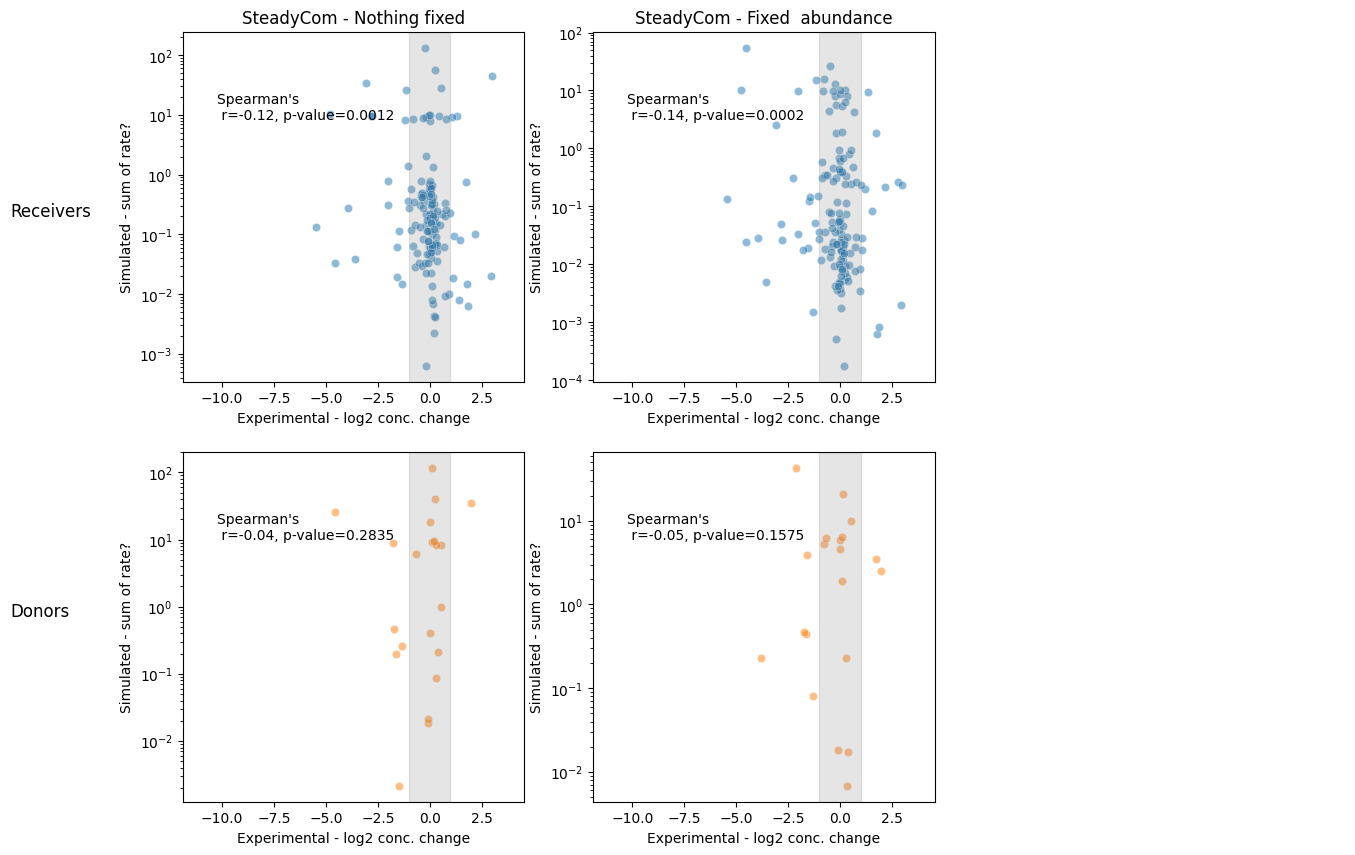

In [13]:

simulation_method="steadycom"
receiver_or_donor="receiver"
agg_method ="sum"
metric = "rate?"

fig,axs = compare_exp_sim.plot_scatter_plots(simulation_dict,
                                             signal_exp,
                   simulation_method=simulation_method,
                   receiver_or_donor=receiver_or_donor,
                   agg_method=agg_method,
                   metric=metric)
axs[0][-1].set_axis_off()
axs[1][-1].set_axis_off()

# Binary system - comparison

## Evaluating changes in scores with changing thresholds

In [14]:
role_config = {
    "receiver": {"exp_cond": "< -1", "freq_thresh": 0.1,  "rate_thresh": 1e-4},
    "donor":    {"exp_cond": "> 1",   "freq_thresh": 0.01, "rate_thresh": 1e-5}
}

exp_sim_bool_dict = compare_exp_sim.run_all_evaluations(simulation_dict, signal_exp, role_config)


[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combin

In [15]:

all_results = {"rate":{},"freq":{}}
for exponent in np.linspace(0.0,6,13):
    sim_thresh = 10**(-exponent)
    role_config["receiver"]["freq_thresh"]=sim_thresh
    role_config["receiver"]["rate_thresh"]=sim_thresh
    
    exp_sim_bool_dict = compare_exp_sim.run_all_evaluations(simulation_dict, signal_exp, role_config)

    sim_bool_dict_rate_rec = compare_exp_sim.merge_eval_results(exp_sim_bool_dict, "receiver", ["steadiercom_rate", "steadycom_rate"])
    sim_bool_dict_freq_rec = compare_exp_sim.merge_eval_results(exp_sim_bool_dict, "receiver", ["steadiercom_frequency", "smetana"])

    scores_df_rate_rec = compare_exp_sim.score_dict_matches(sim_bool_dict_rate_rec)
    scores_df_freq_rec = compare_exp_sim.score_dict_matches(sim_bool_dict_freq_rec)
    
    scores_df_rate_rec.name=f"{sim_thresh}"
    scores_df_freq_rec.name=f"{sim_thresh}"
    all_results["rate"][sim_thresh]=scores_df_rate_rec
    all_results["freq"][sim_thresh] = scores_df_freq_rec

[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combin

### Effect of threshold on rates on scores

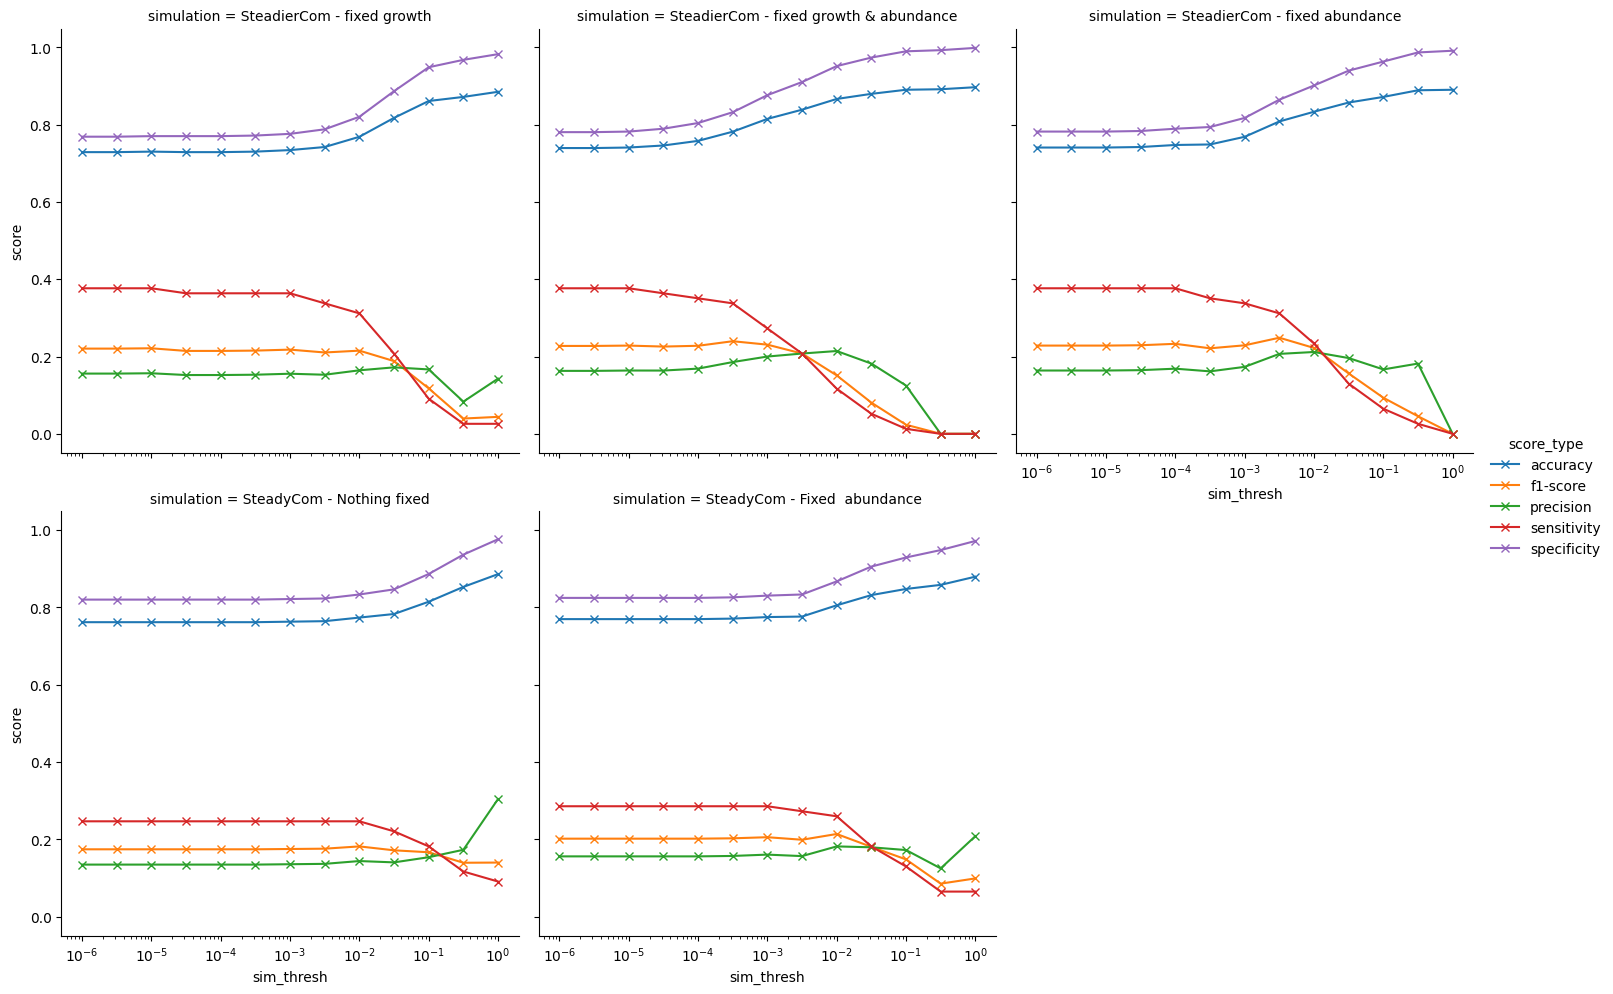

In [16]:
scores = pd.concat(all_results["rate"])

scores_df = scores.stack().reset_index()
scores_df.columns=["sim_thresh","score_type","simulation","score"]


plot = sns.relplot(scores_df,x="sim_thresh",y="score",hue="score_type",col="simulation",kind="line",marker="x",col_wrap=3)
for ax in plot.axes.flat:
    ax.set(xscale="log")
    for line in ax.lines:
        if line.get_marker() != 'None':
            color = line.get_color()
            line.set_markeredgecolor(color)
            line.set_markeredgewidth(1)
            


### Effect of threshold on frequency/mus on scores

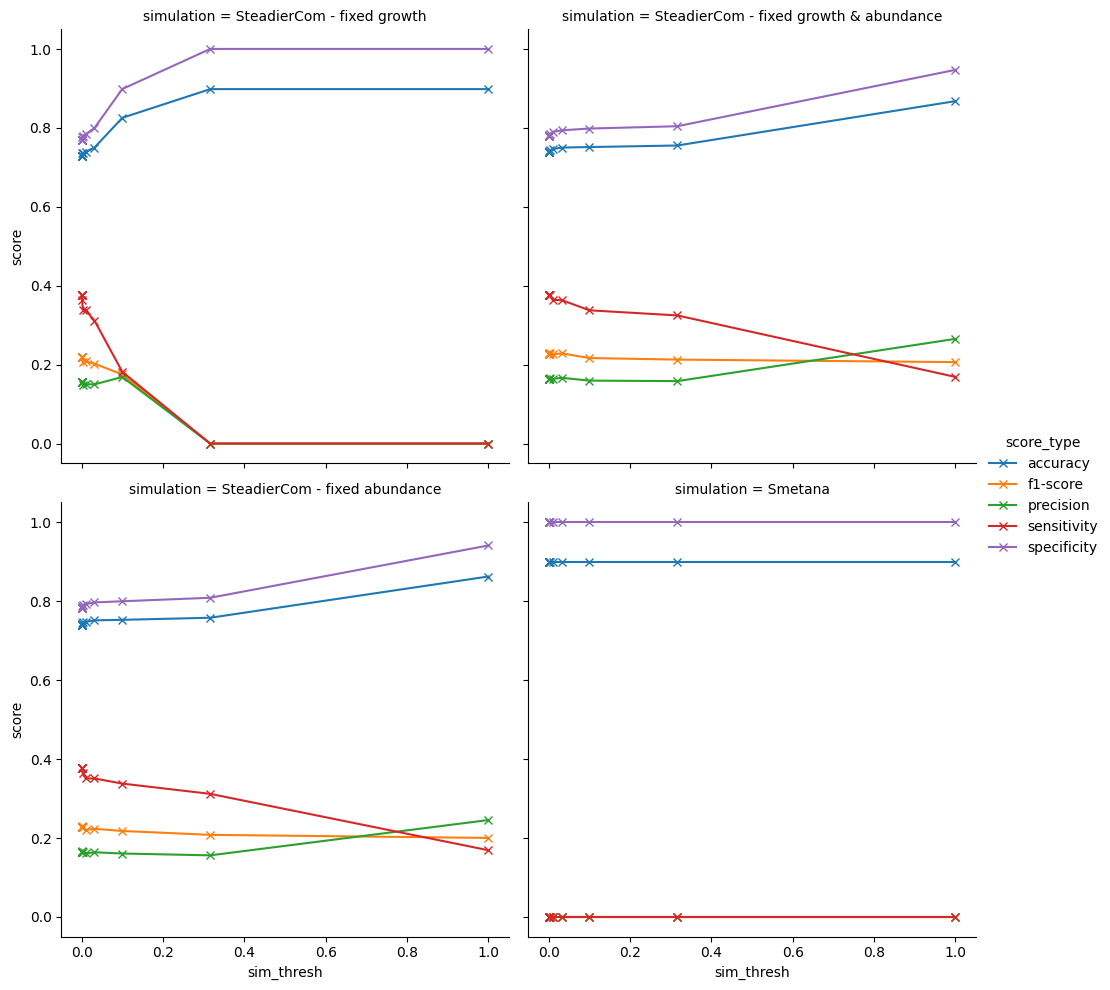

In [17]:
scores = pd.concat(all_results["freq"])

scores_df = scores.stack().reset_index()
scores_df.columns=["sim_thresh","score_type","simulation","score"]


plot = sns.relplot(scores_df,x="sim_thresh",y="score",hue="score_type",col="simulation",kind="line",marker="x",col_wrap=2)
for ax in plot.axes.flat:
    for line in ax.lines:
        if line.get_marker() != 'None':
            color = line.get_color()
            line.set_markeredgecolor(color)
            line.set_markeredgewidth(1)

## Precision-Recall curves

[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


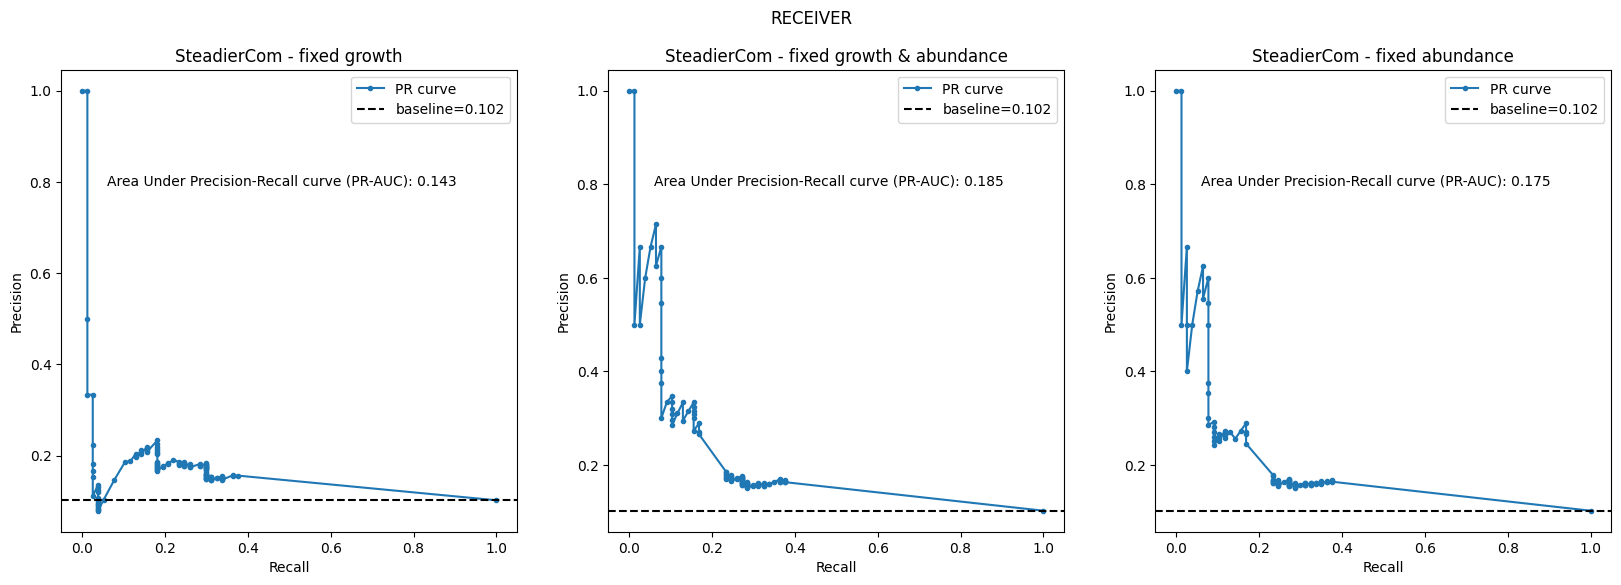

In [18]:
fig,axs = compare_exp_sim.plot_diagnostic_curve(simulation_dict,signal_exp,receiver_or_donor="receiver",simulation_method="steadiercom",metric="frequency",met_column="met_group",agg_method="sum")

[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


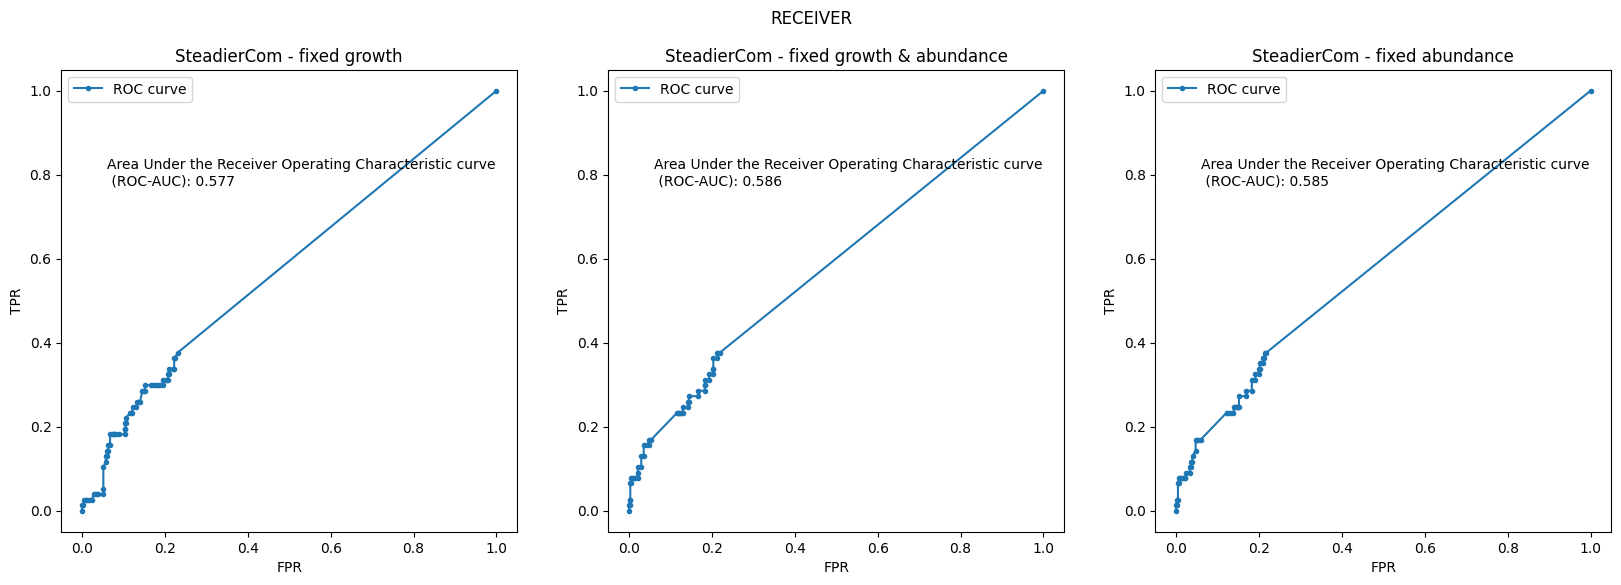

In [19]:
fig,axs = compare_exp_sim.plot_diagnostic_curve(simulation_dict,signal_exp,PR_or_ROC="ROC",receiver_or_donor="receiver",simulation_method="steadiercom",metric="frequency",met_column="met_group",agg_method="sum")

[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


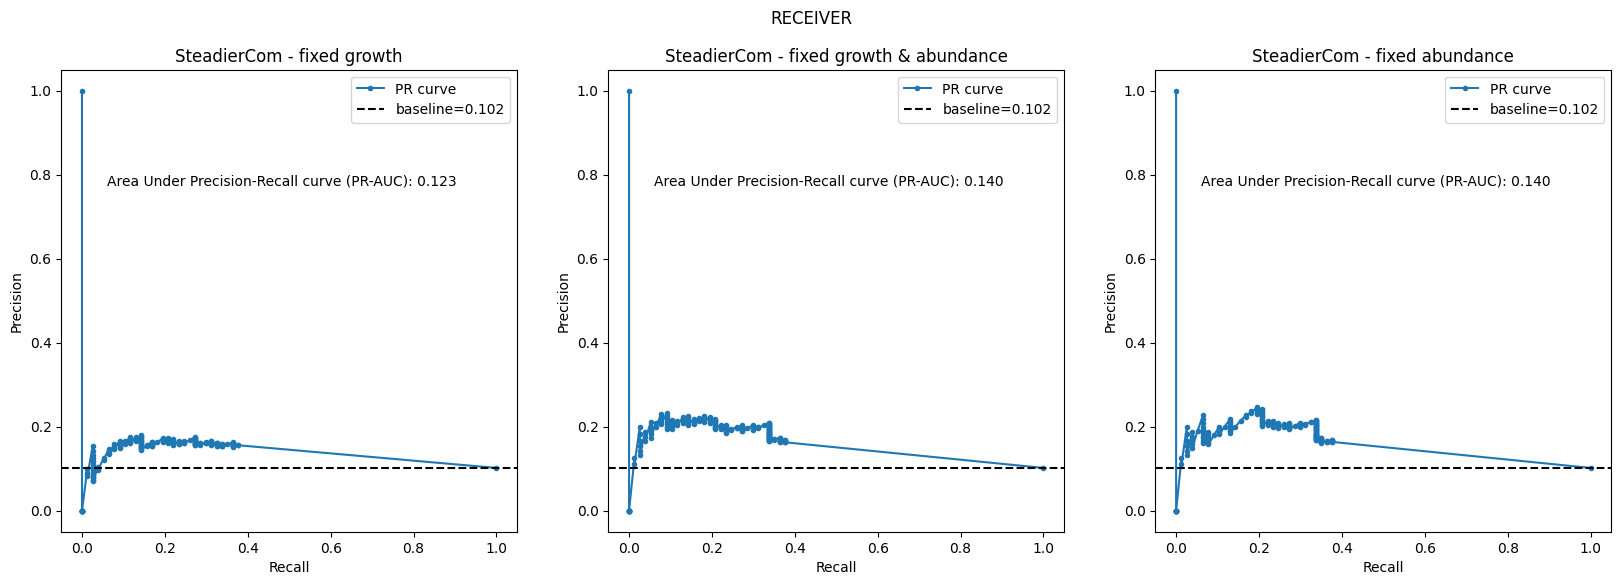

In [20]:
fig,axs =compare_exp_sim.plot_diagnostic_curve(simulation_dict,signal_exp,receiver_or_donor="receiver",simulation_method="steadiercom",metric="rate",met_column="met_group",agg_method="sum")

[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


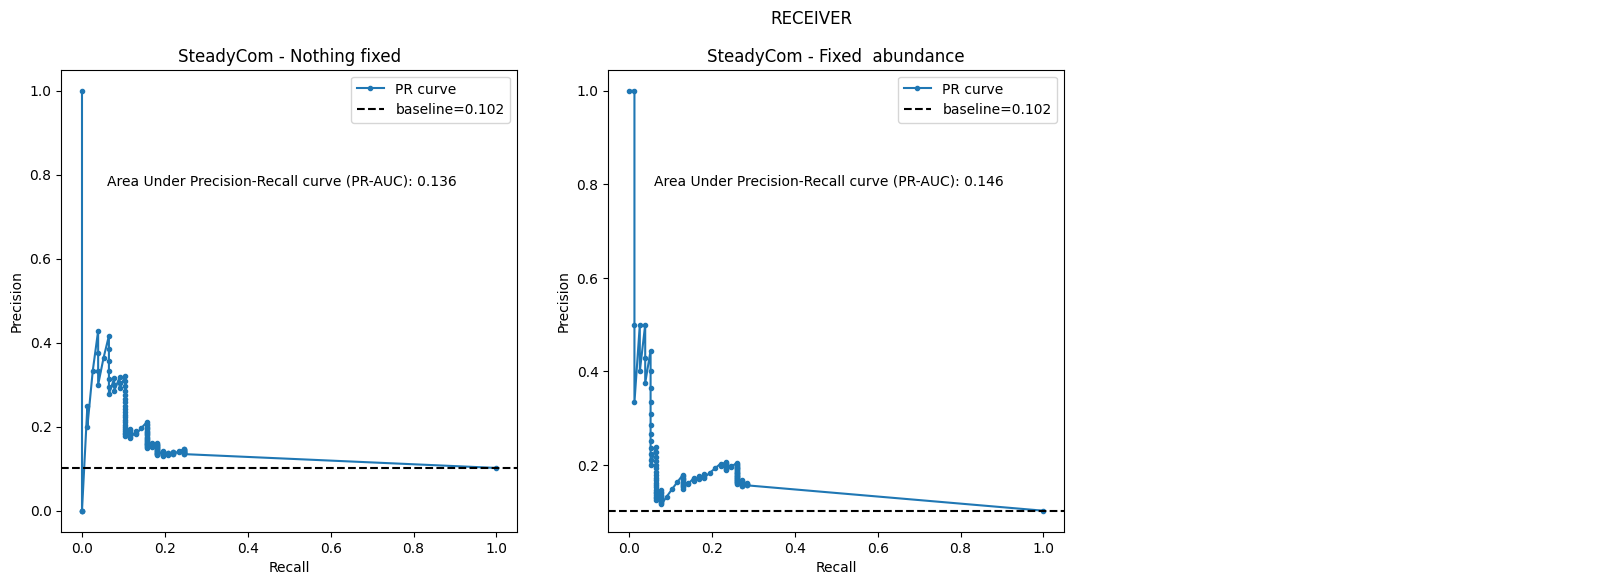

In [21]:
fig,axs = compare_exp_sim.plot_diagnostic_curve(simulation_dict,signal_exp,receiver_or_donor="receiver",simulation_method="steadycom",metric="rate?",met_column="met_group",agg_method="sum")
axs[-1].set_axis_off()

[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


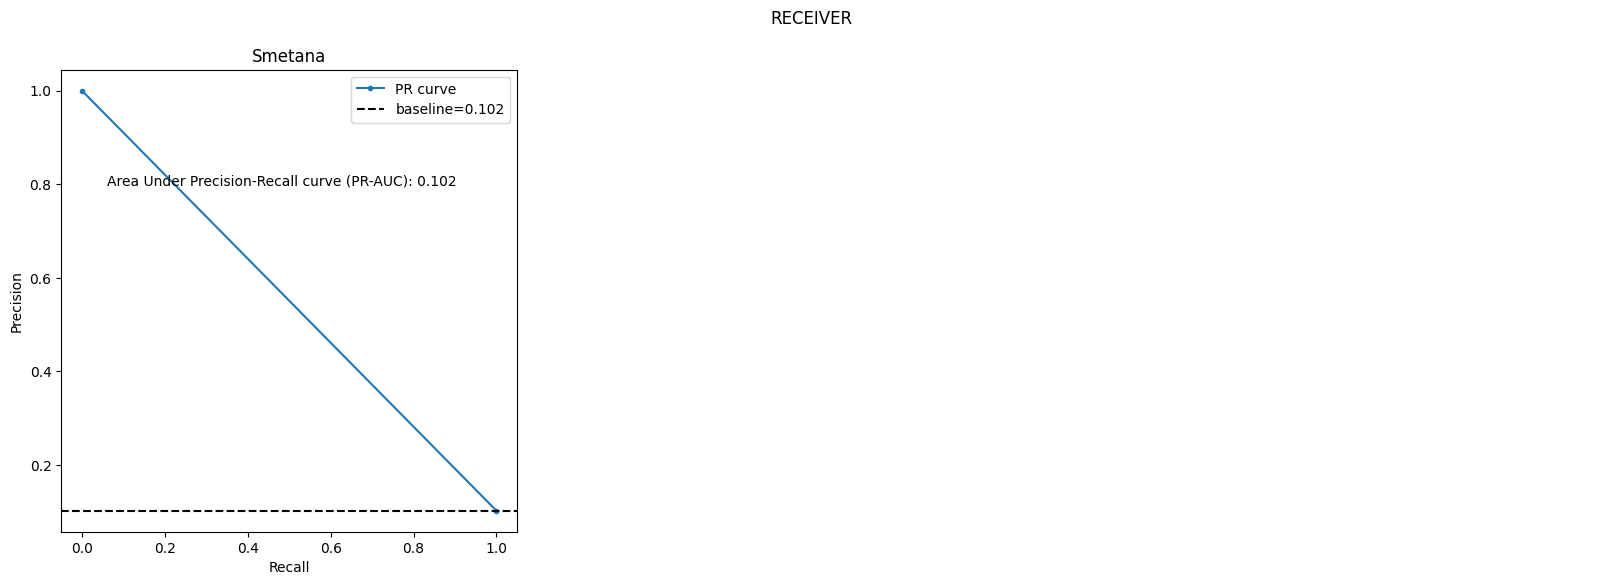

In [22]:
fig,axs = compare_exp_sim.plot_diagnostic_curve(simulation_dict,signal_exp,receiver_or_donor="receiver",simulation_method="smetana",metric="mus",met_column="met_group",agg_method="sum")
axs[-1].set_axis_off()
axs[-2].set_axis_off()

[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


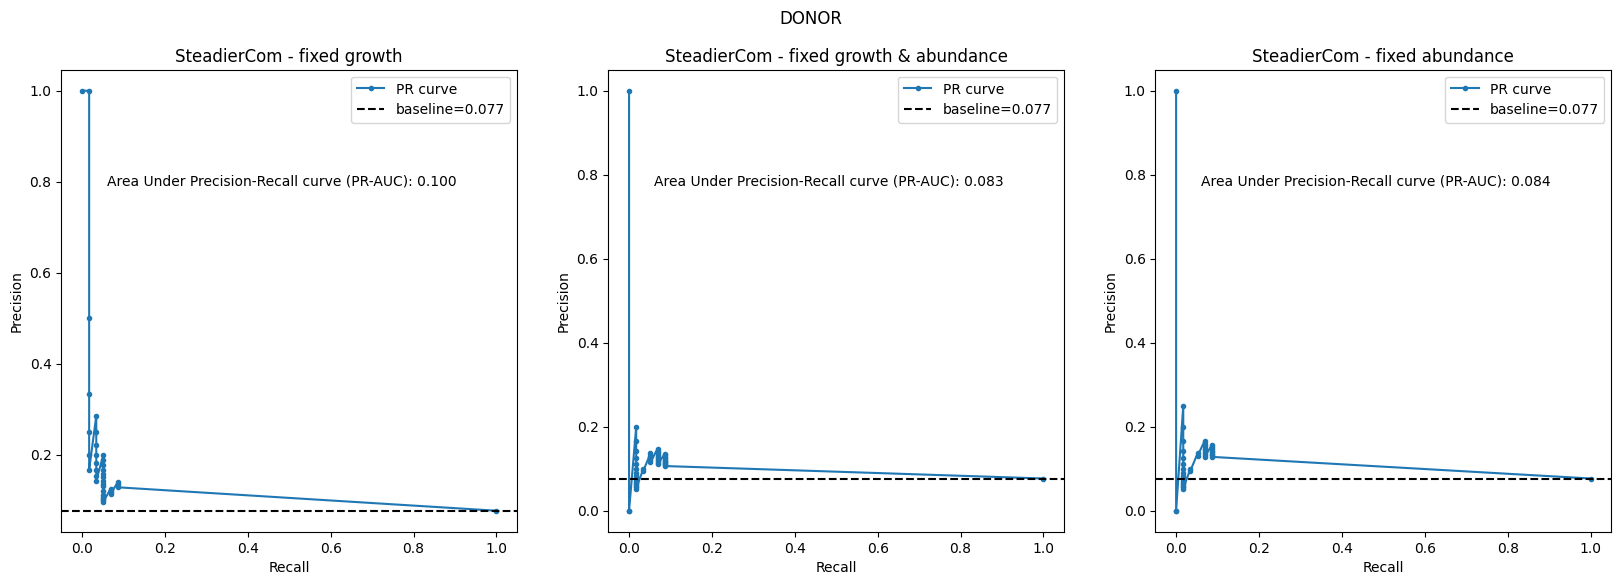

In [23]:
fig,axs = compare_exp_sim.plot_diagnostic_curve(simulation_dict,signal_exp,receiver_or_donor="donor",simulation_method="steadiercom",metric="frequency",met_column="met_group",agg_method="sum")


[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


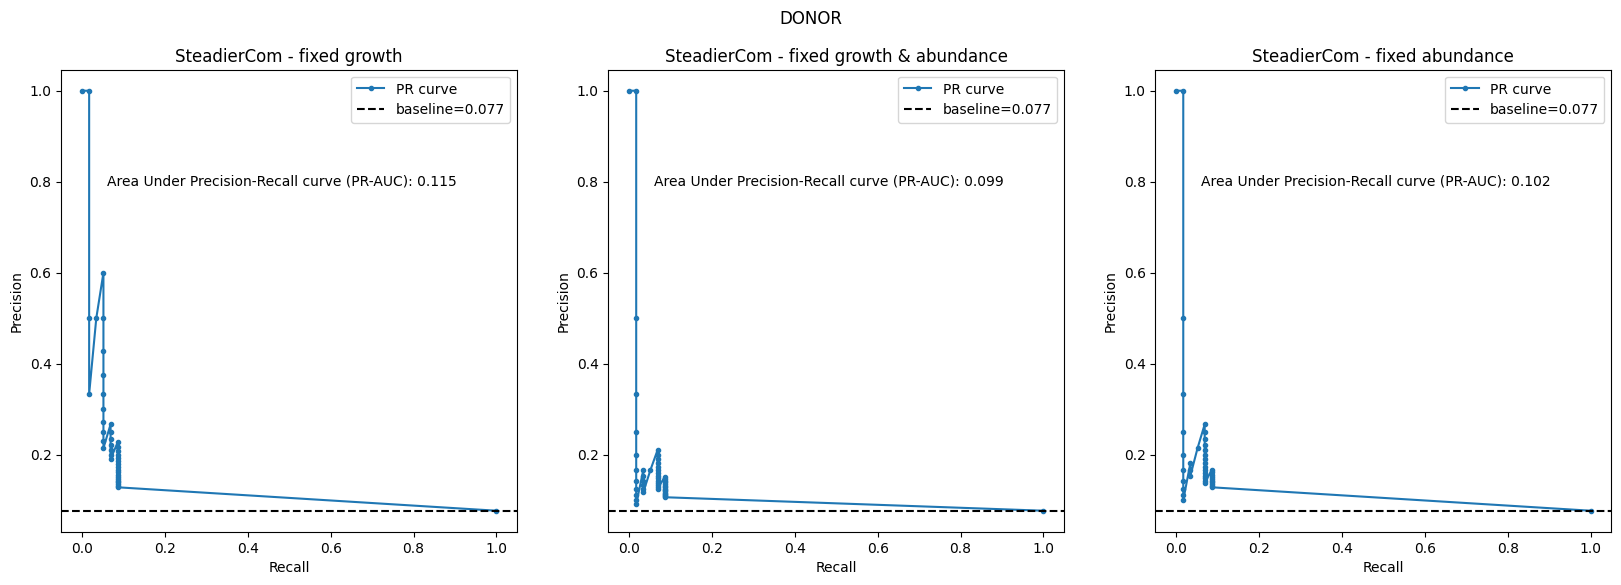

In [24]:
fig,axs = compare_exp_sim.plot_diagnostic_curve(simulation_dict,signal_exp,receiver_or_donor="donor",simulation_method="steadiercom",metric="rate",met_column="met_group",agg_method="sum")

[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object


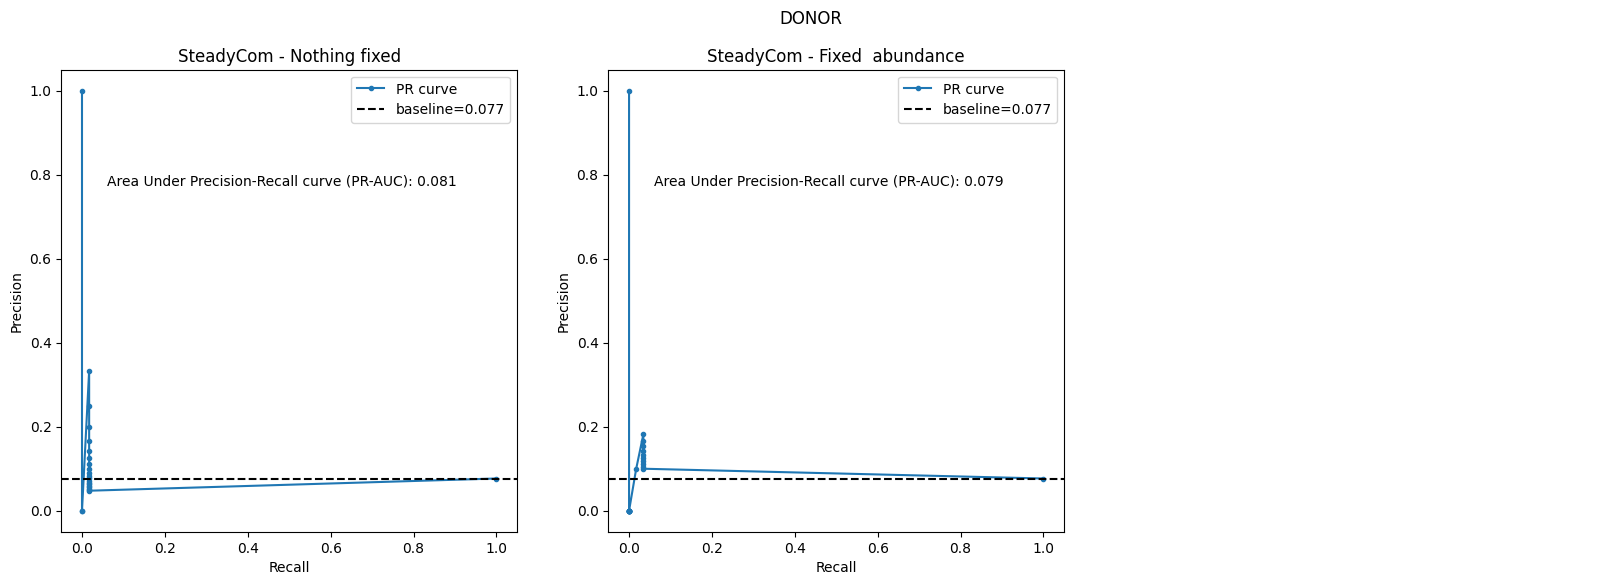

In [25]:
fig,axs = compare_exp_sim.plot_diagnostic_curve(simulation_dict,signal_exp,receiver_or_donor="donor",simulation_method="steadycom",metric="rate?",met_column="met_group",agg_method="sum")
axs[-1].set_axis_off()

## Evaluating methods with fixed thresholds

**Process data - evaluate receiving/donating as true or false for experimental and simulation results**

In [26]:
role_config = {
    "receiver": {"exp_cond": "< -1", "freq_thresh": 0.1,  "rate_thresh": 1e-4},
    "donor":    {"exp_cond": "> 1",   "freq_thresh": 0.01, "rate_thresh": 1e-5}
}

exp_sim_bool_dict = compare_exp_sim.run_all_evaluations(simulation_dict, signal_exp, role_config)


sim_bool_dict_rate_rec = compare_exp_sim.merge_eval_results(exp_sim_bool_dict, "receiver", ["steadiercom_rate", "steadycom_rate"])
sim_bool_dict_freq_rec = compare_exp_sim.merge_eval_results(exp_sim_bool_dict, "receiver", ["steadiercom_frequency", "smetana"])
sim_bool_dict_rate_don = compare_exp_sim.merge_eval_results(exp_sim_bool_dict, "donor",    ["steadiercom_rate", "steadycom_rate"])
sim_bool_dict_freq_don = compare_exp_sim.merge_eval_results(exp_sim_bool_dict, "donor",    ["steadiercom_frequency", "smetana"])

scores_df_rate_rec = compare_exp_sim.score_dict_matches(sim_bool_dict_rate_rec)
scores_df_rate_don = compare_exp_sim.score_dict_matches(sim_bool_dict_rate_don)
scores_df_freq_rec = compare_exp_sim.score_dict_matches(sim_bool_dict_freq_rec)
scores_df_freq_don = compare_exp_sim.score_dict_matches(sim_bool_dict_freq_don)

[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combined object
[INFO] merge_sim_exp removes nan values in 'experiment' column of the return exp_sim_combin

## Confusion matrices

#### Receiver - SteadierCom and SteadyCom - rate

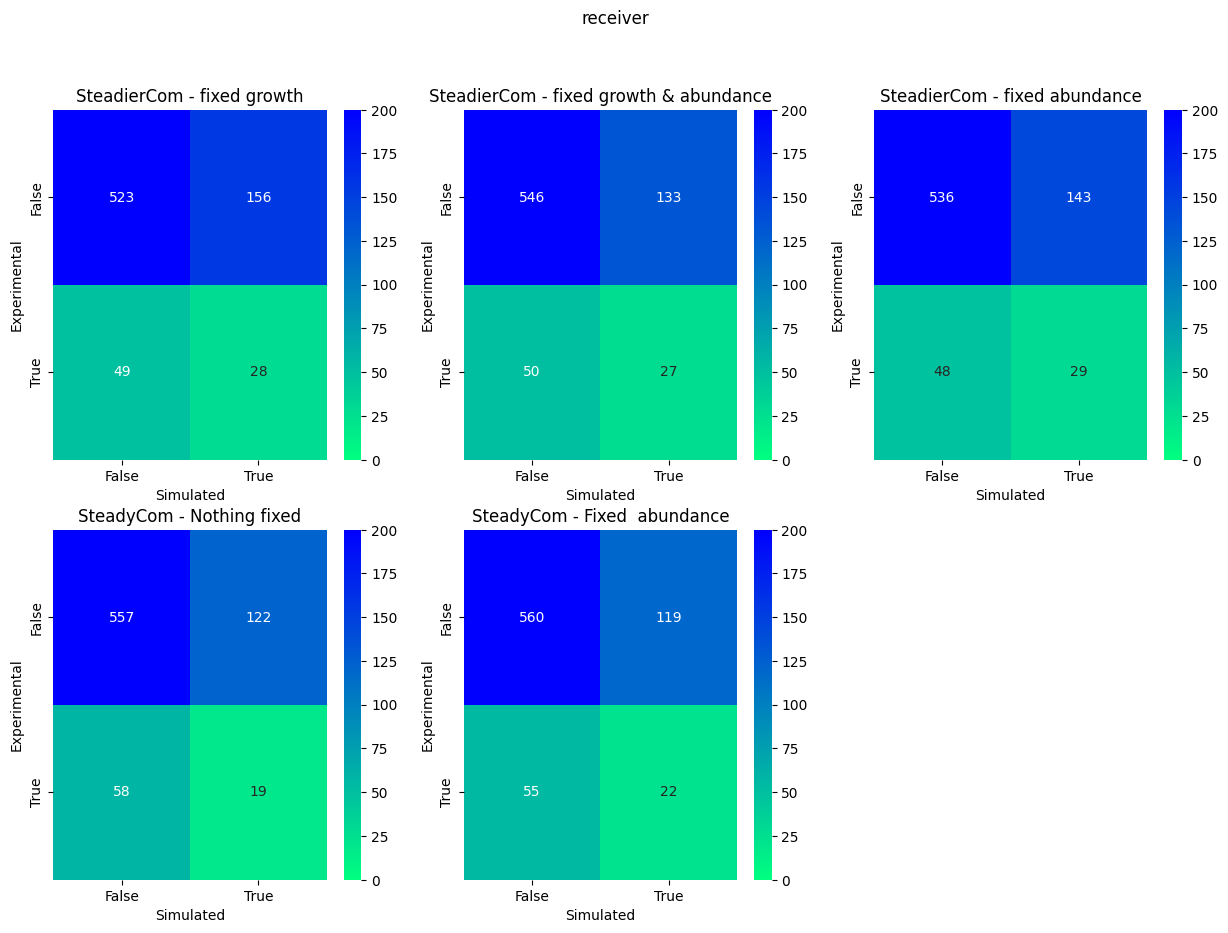

In [27]:
receiver_or_donor="receiver"
fig,axs = compare_exp_sim.plot_confusion_matrix_venturelli(sim_bool_dict_rate_rec,suptitle=receiver_or_donor)
axs[1][-1].set_axis_off()

#### Receiver - SteadierCom and SMETANA - frequency/MUS

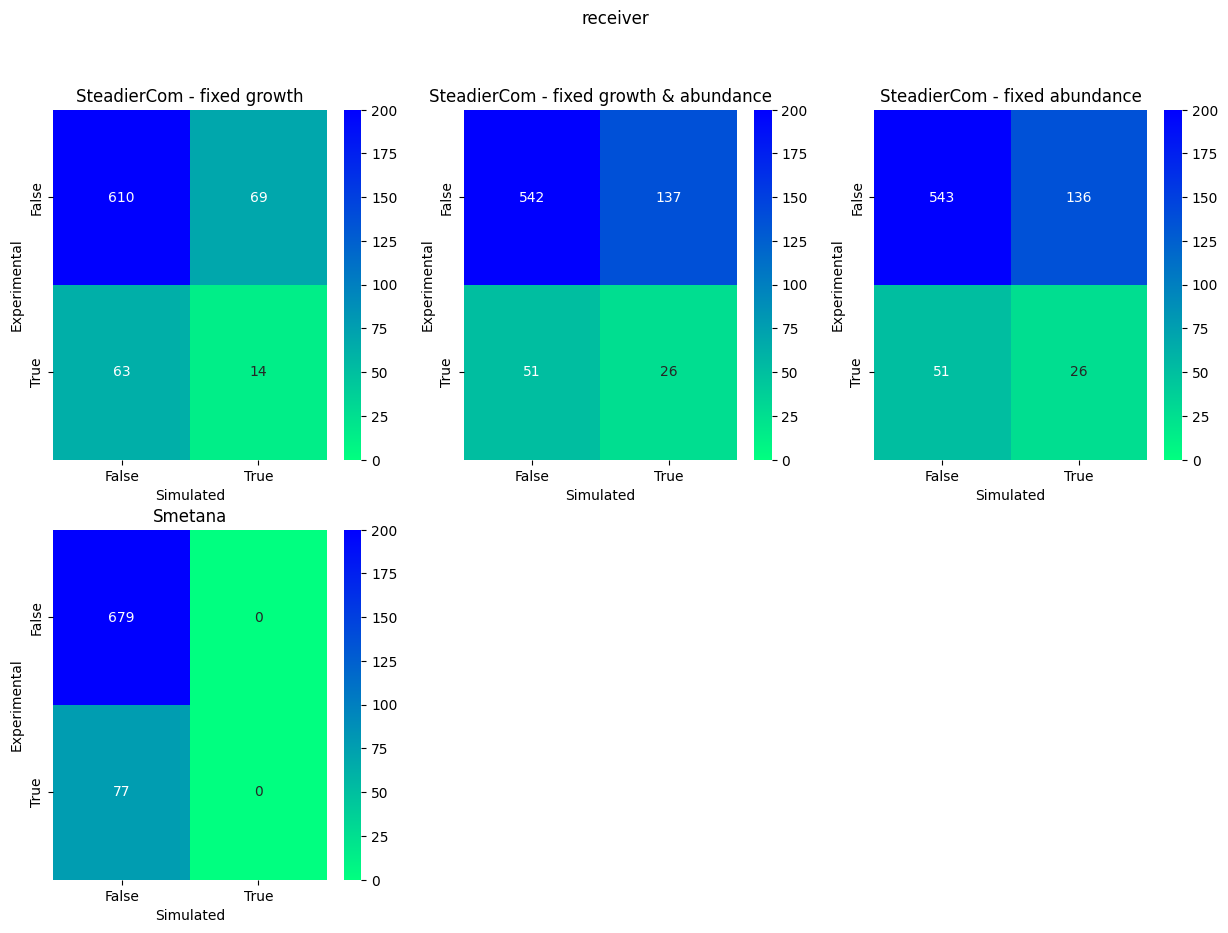

In [28]:
receiver_or_donor="receiver"
fig,axs = compare_exp_sim.plot_confusion_matrix_venturelli(sim_bool_dict_freq_rec,suptitle=receiver_or_donor)

axs[1][-1].set_axis_off()
axs[1][-2].set_axis_off()

#### Donor - SteadierCom and SteadyCom - rate

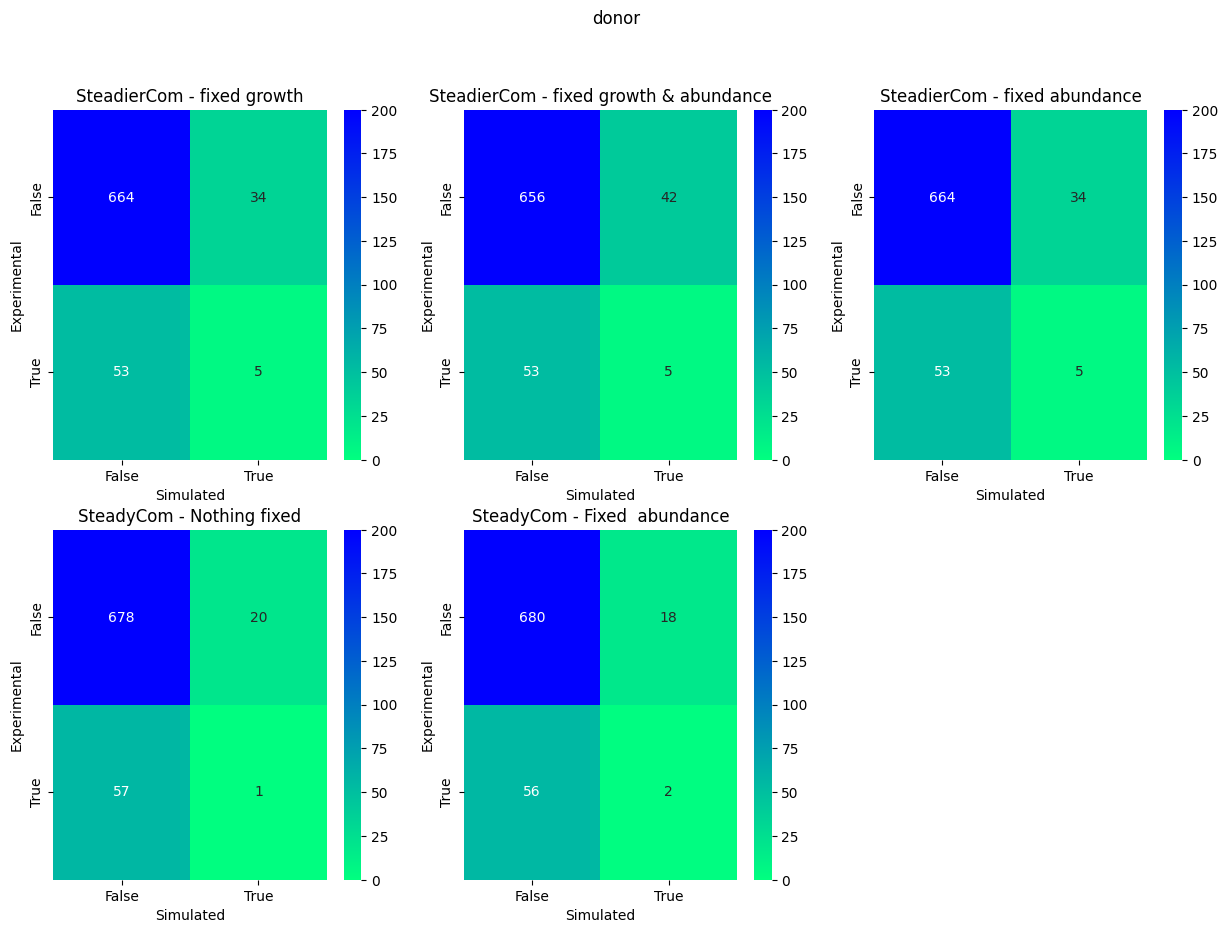

In [29]:
receiver_or_donor="donor"
fig,axs = compare_exp_sim.plot_confusion_matrix_venturelli(sim_bool_dict_rate_don,suptitle=receiver_or_donor)

axs[1][-1].set_axis_off()

#### Donor - SteadierCom and SMETANA - frequency/MUS

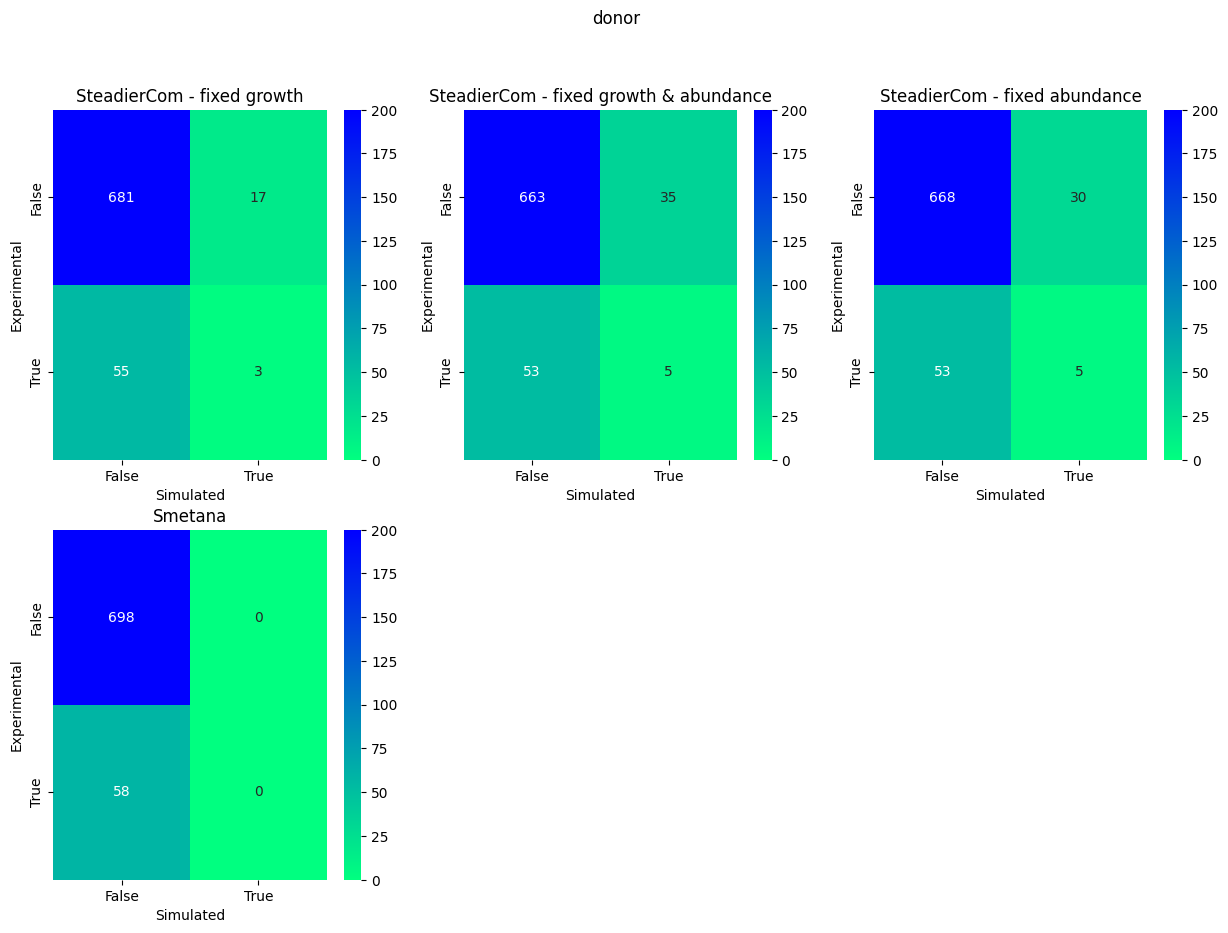

In [30]:
receiver_or_donor="donor"
fig,axs = compare_exp_sim.plot_confusion_matrix_venturelli(sim_bool_dict_freq_don,suptitle=receiver_or_donor)

axs[1][-1].set_axis_off()
axs[1][-2].set_axis_off()

## Radar charts

### Receivers - SteadyCom vs SteadierCom - rate

Text(0.5, 0.98, 'receiver')

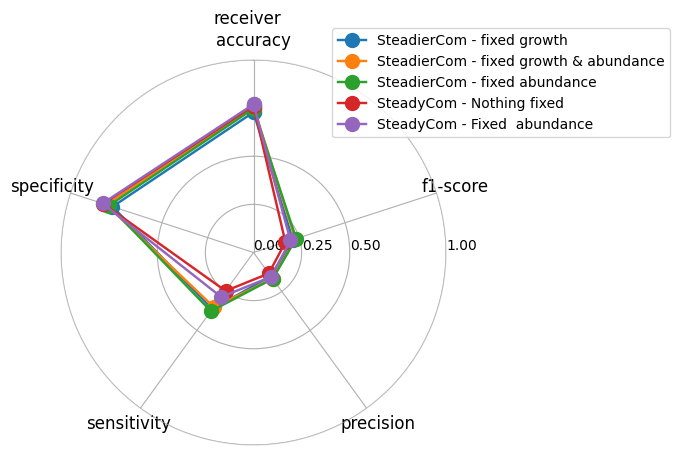

In [31]:
receiver_or_donor="receiver"
fig, ax = compare_exp_sim.plot_radar_chart(scores_df_rate_rec)
fig.suptitle(receiver_or_donor)

### Receivers - SteadierCom - frequency

Text(0.5, 0.98, 'receiver')

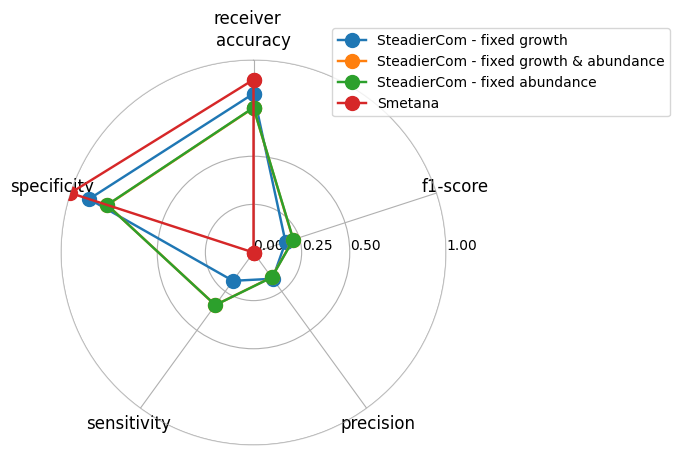

In [32]:
fig, ax = compare_exp_sim.plot_radar_chart(scores_df_freq_rec)
fig.suptitle(receiver_or_donor)

### Donors - SteadyCom vs SteadierCom - rate

Text(0.5, 0.98, 'donor')

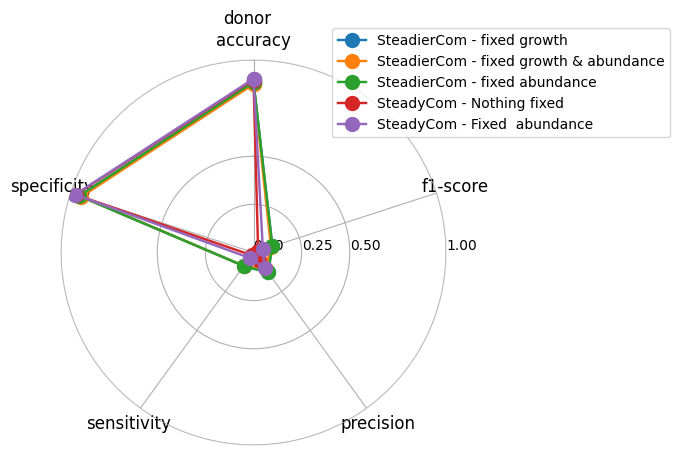

In [33]:
receiver_or_donor="donor"
fig, ax = compare_exp_sim.plot_radar_chart(scores_df_rate_don)
fig.suptitle(receiver_or_donor)

### Donors - SteadierCom - frequency

Text(0.5, 0.98, 'donor')

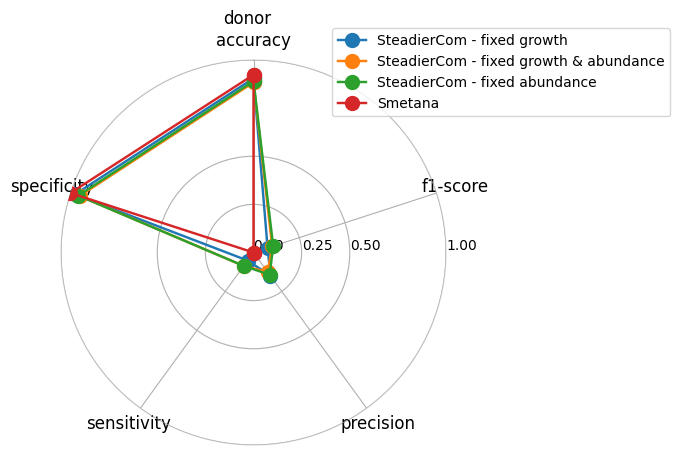

In [34]:
receiver_or_donor ="donor"

fig, ax = compare_exp_sim.plot_radar_chart(scores_df_freq_don)
fig.suptitle(receiver_or_donor)

### Direct interactions

In [35]:
def prepare_sim_met_venturelli(simulated_results,metid2group):
    
    """
    Function to create new column in simulation results with metabolite group "met_group" and to filter out results we are not interested in.
    """

    # Map met id to met group

    simulated_results = simulated_results[(simulated_results.donor!="environment") & (simulated_results.receiver!="environment")].copy()
    simulated_results = simulated_results[~simulated_results.donor.isna()].copy()
    simulated_results = simulated_results[~simulated_results.receiver.isna()].copy()
    simulated_results.donor = simulated_results.donor.map(lambda x: x.split("_")[0][0].upper()+x.split("_")[1][0].upper())
    simulated_results.receiver = simulated_results.receiver.map(lambda x: x.split("_")[0][0].upper()+x.split("_")[1][0].upper())

    
    simulated_res_reduced = simulated_results[simulated_results.compound.isin(metid2group.keys())].copy()
    simulated_res_reduced["met_group"] = simulated_res_reduced.compound.map(lambda x: metid2group[x])
    
    return simulated_res_reduced

def prepare_all_simulations_venturelli(sim_dicts, metid2group,verbose=True):
    """
    Function to prepare all simulation results for analysis with prepare_sim_met_venturelli.
    """
    
    simulation_dict = {}

    for method, sim_data in sim_dicts.items():
        simulation_dict[method] = {
            name: prepare_sim_met_venturelli(
                simulated_results=res,
                metid2group=metid2group,
            )
            for name, res in sim_data.items()
            }
    return simulation_dict

def prepare_exp_coop(dataset4,metname_groups,metname2group,threshold=1):
    
    signal_exp = compare_exp_sim.prepare_exp_met_venturelli(dataset4,metname_groups,metname2group)
    receivers_ds4 = (signal_exp<-threshold).rename_axis(["receiver","met_group"])
    donors_ds4 = (signal_exp>threshold).rename_axis(["donor","met_group"])

    receivers_ds4 = receivers_ds4.reset_index(name="value")
    donors_ds4 =donors_ds4.reset_index(name="value")

    merged = pd.merge(left=receivers_ds4,right=donors_ds4,on="met_group")
    merged["value"] = (merged["value_x"]*merged["value_y"]).map(int)
    merged.drop(columns=["value_x","value_y"])

    exp_signal_coop = merged.set_index(["receiver","donor","met_group"])["value"]
    return exp_signal_coop

from sklearn.metrics import confusion_matrix,recall_score,precision_score,classification_report,average_precision_score, roc_auc_score,precision_recall_curve,roc_curve

def plot_diagnostic_curve(simulation_dict,exp_signal,PR_or_ROC="PR",simulation_method="steadiercom",metric="frequency",met_column="met_group",agg_method="sum",verbose=True):
    fig,axs =  plt.subplots(1,3,figsize=(20, 6))
    
    i=0
    for name,sim_df in simulation_dict[simulation_method].items():
        sim_signal =sim_df.groupby(["receiver","donor",met_column]).sum()[metric]

        sim_signal = sim_signal.reindex(exp_signal.index,fill_value=0)

        y_true=exp_signal.values
        y_scores=sim_signal.values

        ax=axs[i]
        if PR_or_ROC=="PR":
            baseline = sum(y_true)/len(y_true)
            auc = average_precision_score(y_true, y_scores)
            precision, recall, thresholds = precision_recall_curve(y_true, y_scores)
            # Plot the curve

            ax.plot(recall, precision, marker='.', label='PR curve')
            ax.set_xlabel('Recall')
            ax.set_ylabel('Precision')
            plt.text(.1, .75, f"Area Under Precision-Recall curve (PR-AUC): {auc:.3f}",transform=ax.transAxes)

            ax.axhline(y=baseline, color='black', linestyle='--',label=f"baseline={baseline:.3f}")
        elif PR_or_ROC=="ROC":
            auc = roc_auc_score(y_true, y_scores)
            fpr, tpr, thresholds = roc_curve(y_true, y_scores)
            # Plot the curve

            ax.plot(fpr, tpr, marker='.', label='ROC curve')
            ax.set_xlabel('FPR')
            ax.set_ylabel('TPR')

            plt.text(.1, .75, f"Area Under the Receiver Operating Characteristic curve \n (ROC-AUC): {auc:.3f}",transform=ax.transAxes)

        ax.set_title(f"{name}")
        ax.legend()

        i+=1
    return fig,axs

In [36]:
simulation_dict_new = prepare_all_simulations_venturelli(simulation_sources,metid2group)

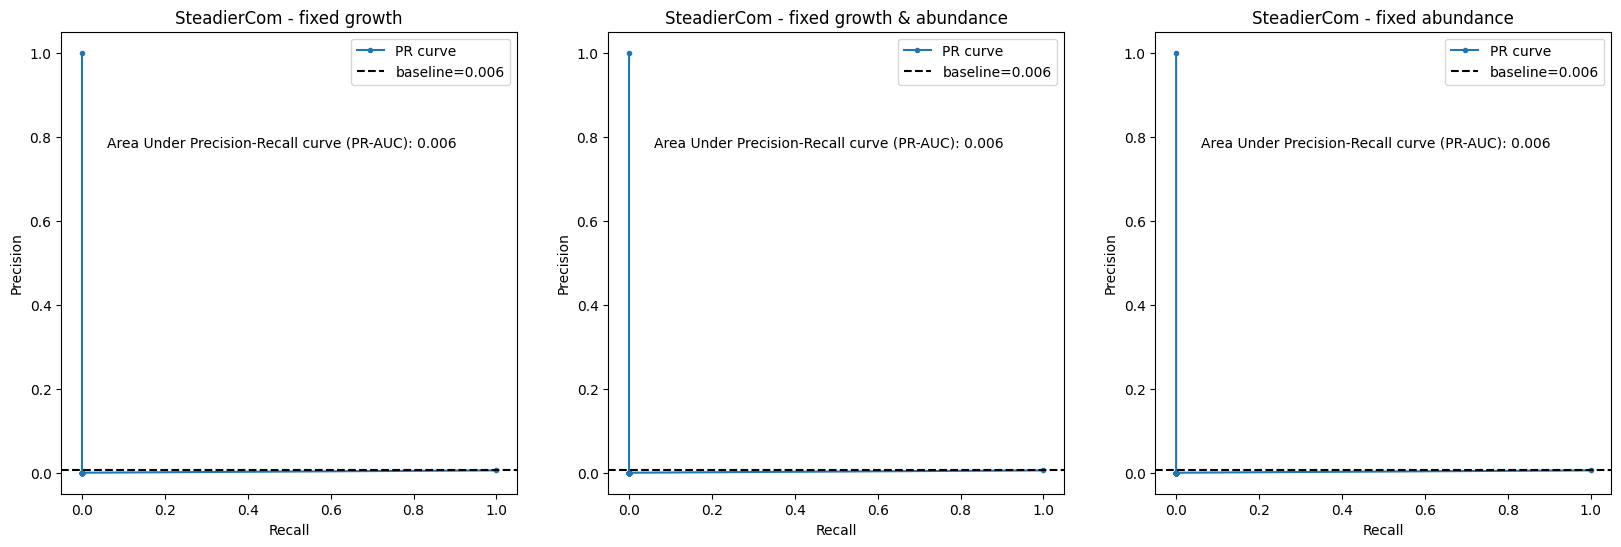

In [41]:
exp_signal_coop= prepare_exp_coop(dataset4,metname_groups,metname2group,threshold=1)

fig,axs = plot_diagnostic_curve(simulation_dict_new,exp_signal_coop,metric="frequency")
plt.savefig("don_met_rec_steadiercom_1.png")

In [44]:
exp_signal_coop[exp_signal_coop>0]

receiver  donor  met_group              
BU        CH     Cytidine pool              1
          CA     Cytosine pool              1
          CH     Cytosine pool              1
BT        BU     Guanine pool               1
          FP     Guanine pool               1
          CH     Guanine pool               1
ER        PC     2-ketobutyric acid pool    1
          BU     Adenine pool               1
          BT     Adenine pool               1
          BO     Adenine pool               1
          CH     Adenine pool               1
          BU     Feruloylputrescine pool    1
                 Uric acid pool             1
          BT     Uric acid pool             1
          BO     Uric acid pool             1
          PC     Uric acid pool             1
          BT     Xanthine pool              1
          BO     Xanthine pool              1
          BV     Xanthine pool              1
          FP     Xanthine pool              1
CA        BU     Adenine pool          

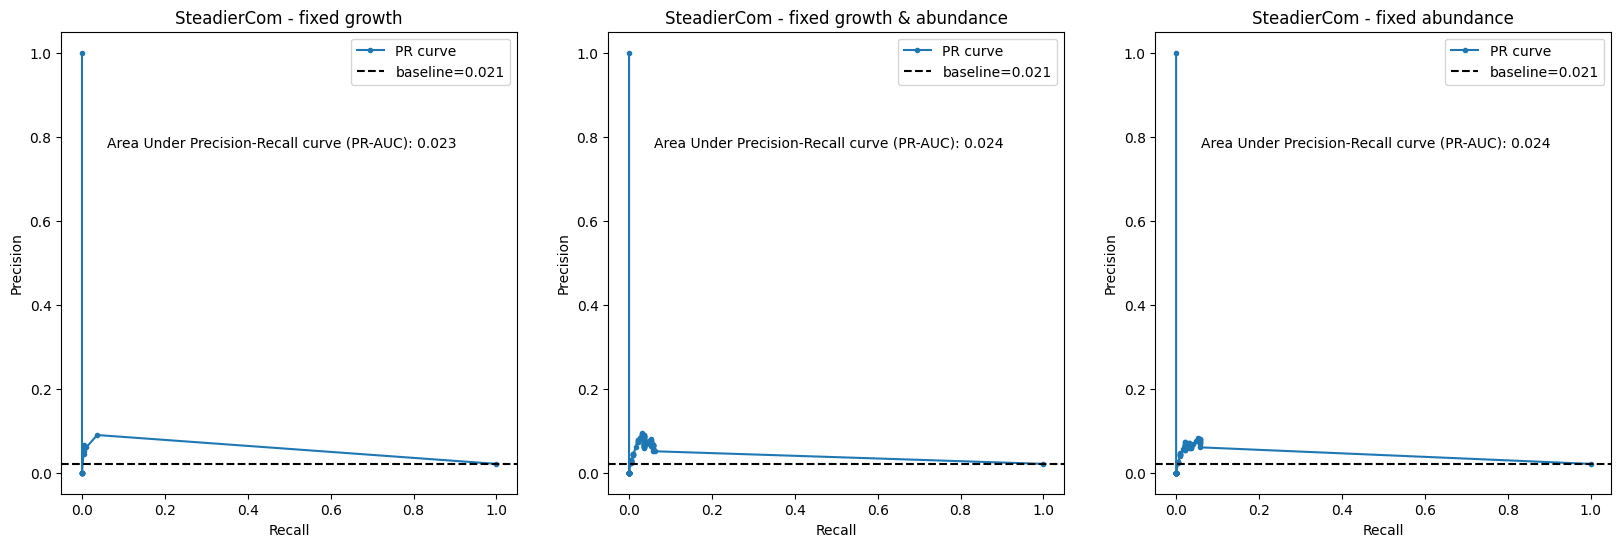

In [39]:
exp_signal_coop= prepare_exp_coop(dataset4,metname_groups,metname2group,threshold=0.5)

fig,axs = plot_diagnostic_curve(simulation_dict_new,exp_signal_coop)
plt.savefig("don_met_rec_steadiercom_05.png")

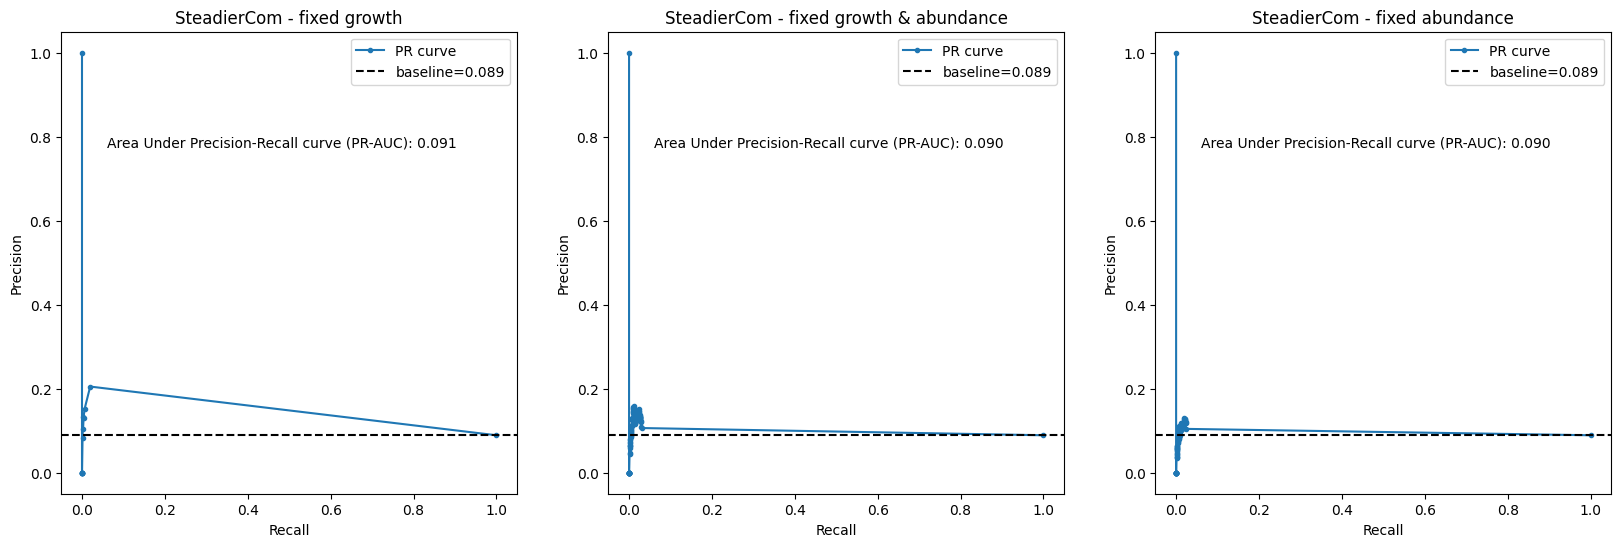

In [39]:
exp_signal_coop= prepare_exp_coop(dataset4,metname_groups,metname2group,threshold=0.1)

fig,axs = plot_diagnostic_curve(simulation_dict_new,exp_signal_coop)
plt.savefig("don_met_rec_steadiercom_01.png")

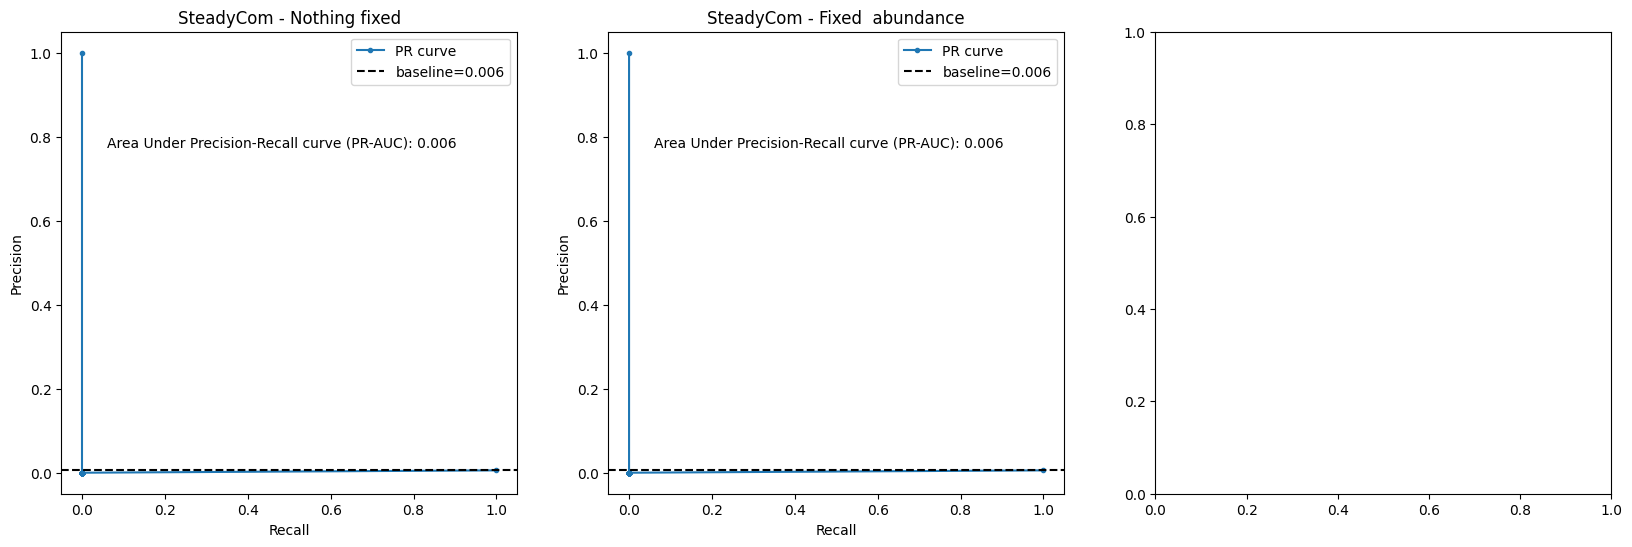

In [40]:
exp_signal_coop= prepare_exp_coop(dataset4,metname_groups,metname2group,threshold=1)

fig,axs = plot_diagnostic_curve(simulation_dict_new,exp_signal_coop,metric="rate?",simulation_method="steadycom")
plt.savefig("don_met_rec_steadycom_1.png")

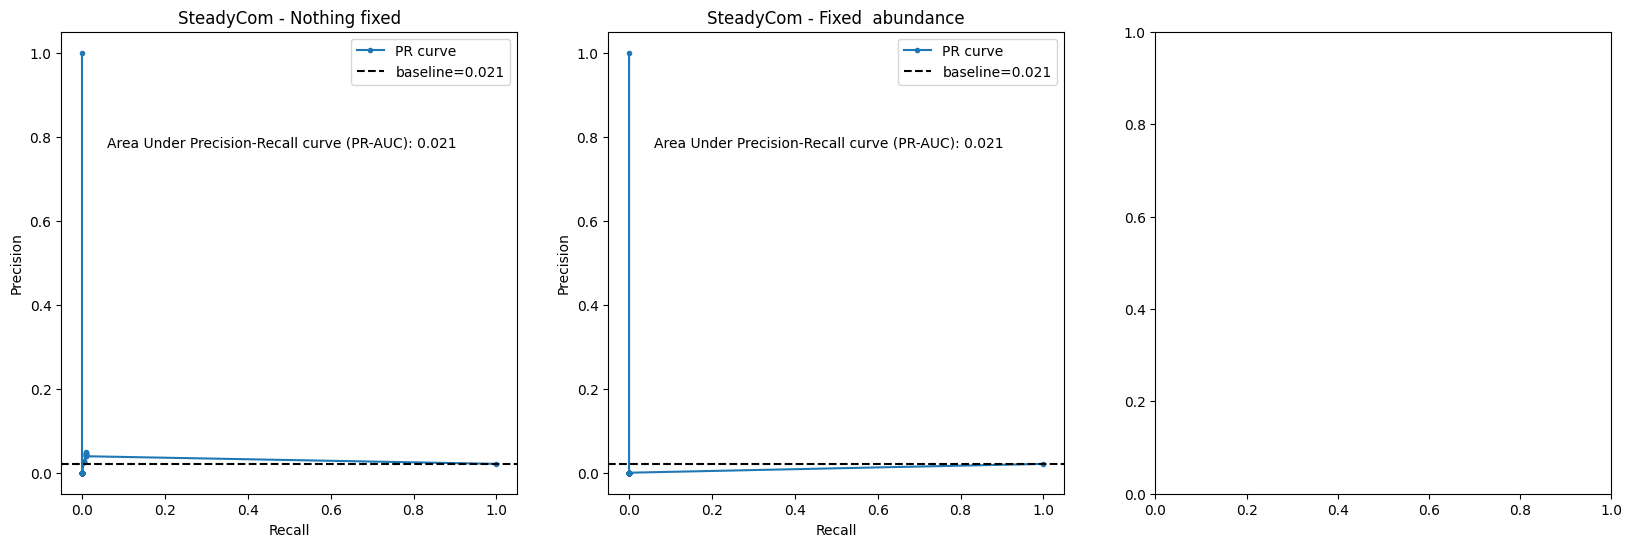

In [41]:
exp_signal_coop= prepare_exp_coop(dataset4,metname_groups,metname2group,threshold=0.5)

fig,axs = plot_diagnostic_curve(simulation_dict_new,exp_signal_coop,metric="rate?",simulation_method="steadycom")
plt.savefig("don_met_rec_steadycom_05.png")

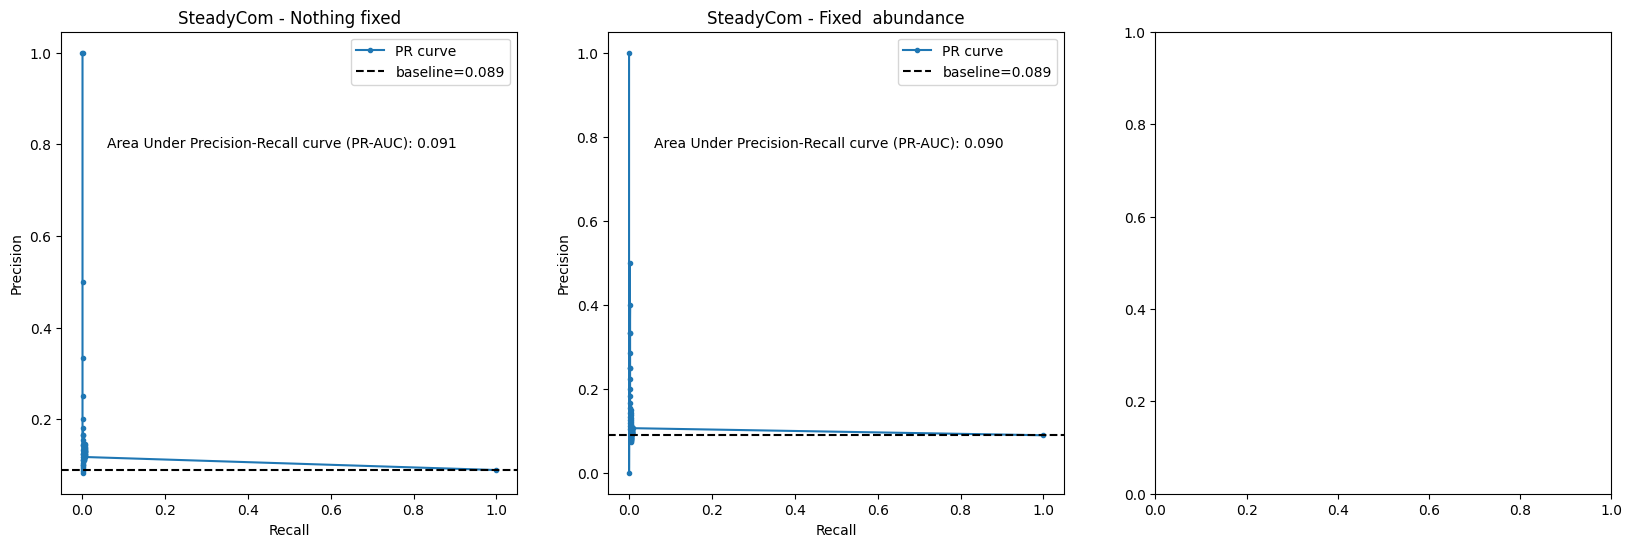

In [42]:
exp_signal_coop= prepare_exp_coop(dataset4,metname_groups,metname2group,threshold=0.1)

fig,axs = plot_diagnostic_curve(simulation_dict_new,exp_signal_coop,metric="rate?",simulation_method="steadycom")
plt.savefig("don_met_rec_steadycom_01.png")

In [102]:
steadiercom_growth_prep = preprocessing_func(steadiercom_growth)
steadiercom_growth_prep = steadiercom_growth_prep[(steadiercom_growth_prep.donor!="environment") & (steadiercom_growth_prep.receiver!="environment")]
steadiercom_growth_prep[steadiercom_growth_prep.frequency>0.001].sort_values("mass_rate*frequency")

,donor,receiver,compound,mass_rate,rate,frequency,community,medium,mass_rate*frequency,super_class
1056,Collinsella_aerofaciens_ATCC_25986,Eubacterium_rectale_ATCC_33656,M_nh4__91__e__93__,0.000011,0.000592,0.002333,NONE,LB_extend,2.492598e-08,inorganic ions and atoms
1042,Eggerthella_lenta_DSM_2243,Clostridium_hiranonis_TO_931_DSM_13275,M_for__91__e__93__,0.000019,0.000413,0.002000,NONE,LB_extend,3.714287e-08,carboxylic acids and anions
1027,Faecalibacterium_prausnitzii_A2_165,Clostridium_hiranonis_TO_931_DSM_13275,M_for__91__e__93__,0.000037,0.000831,0.001333,NONE,LB_extend,4.989648e-08,carboxylic acids and anions
1039,Faecalibacterium_prausnitzii_A2_165,Eubacterium_rectale_ATCC_33656,M_nh4__91__e__93__,0.000024,0.001346,0.002667,NONE,LB_extend,6.472363e-08,inorganic ions and atoms
1017,Eubacterium_rectale_ATCC_33656,Bacteroides_vulgatus_ATCC_8482,M_nh4__91__e__93__,0.000048,0.002669,0.001667,NONE,LB_extend,8.023938e-08,inorganic ions and atoms
...,...,...,...,...,...,...,...,...,...,...
65,Prevotella_copri_CB7_DSM_18205,Blautia_hydrogenotrophica_DSM_10507,M_nzp__91__e__93__,0.176688,0.628190,0.001333,NONE,LB_extend,2.355843e-04,other
162,Clostridium_hiranonis_TO_931_DSM_13275,Collinsella_aerofaciens_ATCC_25986,M_12dhchol__91__e__93__,0.069814,0.172149,0.011667,NONE,LB_extend,8.145025e-04,other
159,Collinsella_aerofaciens_ATCC_25986,Clostridium_hiranonis_TO_931_DSM_13275,M_cholate__91__e__93__,0.070162,0.172149,0.011667,NONE,LB_extend,8.185510e-04,other
100,Clostridium_hiranonis_TO_931_DSM_13275,Eggerthella_lenta_DSM_2243,M_12dhchol__91__e__93__,0.120414,0.296919,0.013000,NONE,LB_extend,1.565386e-03,other


In [106]:
steadiercom_growth_prep.sort_values("mass_rate*frequency",ascending=False).head(100).compound.unique()

array(['M_cholate__91__e__93__', 'M_12dhchol__91__e__93__',
       'M_nzp__91__e__93__', 'M_anzp__91__e__93__', 'M_fru__91__e__93__',
       'M_lac_D__91__e__93__', 'M_C02528__91__e__93__',
       'M_3dhcdchol__91__e__93__', 'M_czp__91__e__93__',
       'M_orn__91__e__93__', 'M_7a_czp__91__e__93__',
       'M_for__91__e__93__', 'M_3dhchol__91__e__93__',
       'M_lac_L__91__e__93__', 'M_acald__91__e__93__',
       'M_etoh__91__e__93__', 'M_co2__91__e__93__'], dtype=object)